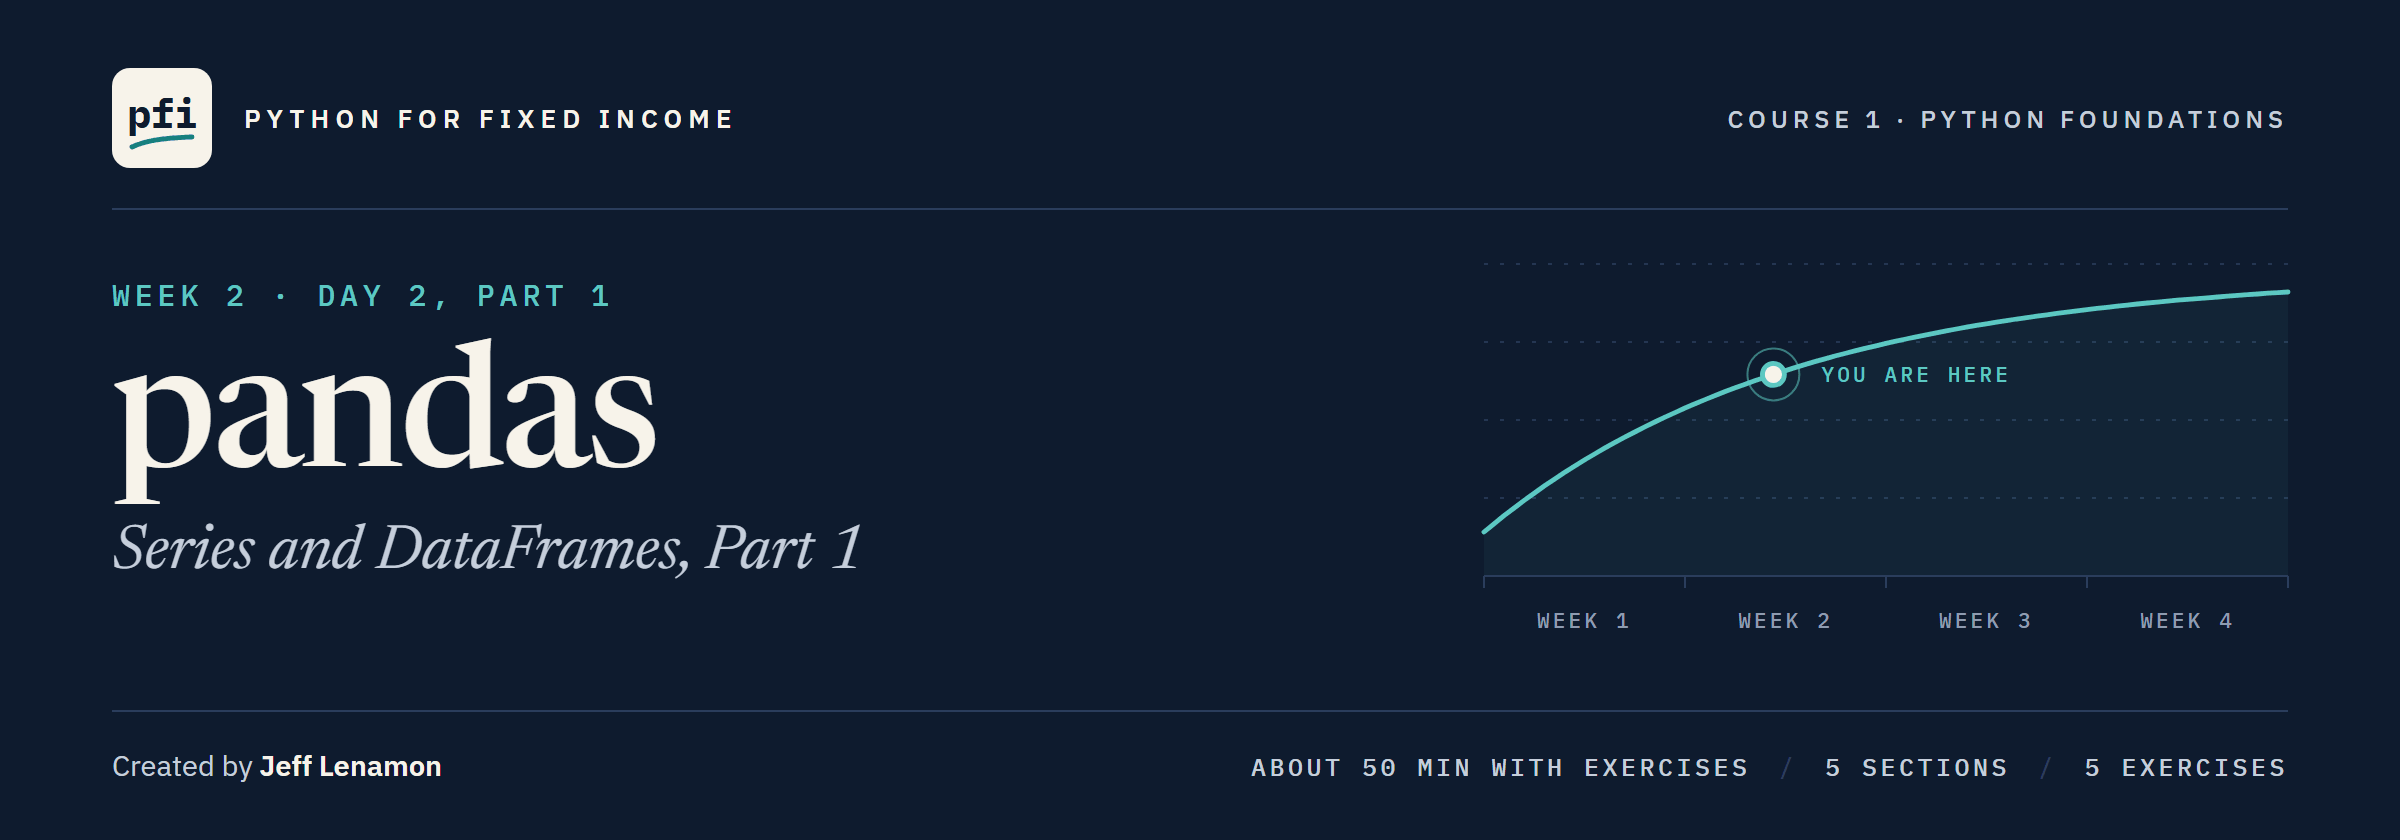

# pandas: Series and DataFrames, Part 1

Week 2, Day 2, Part 1. Holding a whole portfolio in one table, and pulling out the rows and columns a question needs.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week2/day2/07_pandas_series_and_dataframes.ipynb)

## The Desk Lead's Tenth Note

> Yesterday's file came back without its tickers. Today the book is two hundred bonds in `holdings.csv`. First put names on our four bonds, and check the coupon income still ties when the other system sends the faces in its own order, and when it leaves one out. Then load the file: how big, which columns, anything missing. Show me the spreads, and pull up CUSIP 99039NAC0 and its price.

**pandas** holds a table: text and numbers side by side, a name on every row and column.
A **Series** is one labelled column; a **DataFrame** is a table of them.
The issuers are invented.

**Start with one column: four prices.**

## Your Route Through Day 2, Part 1

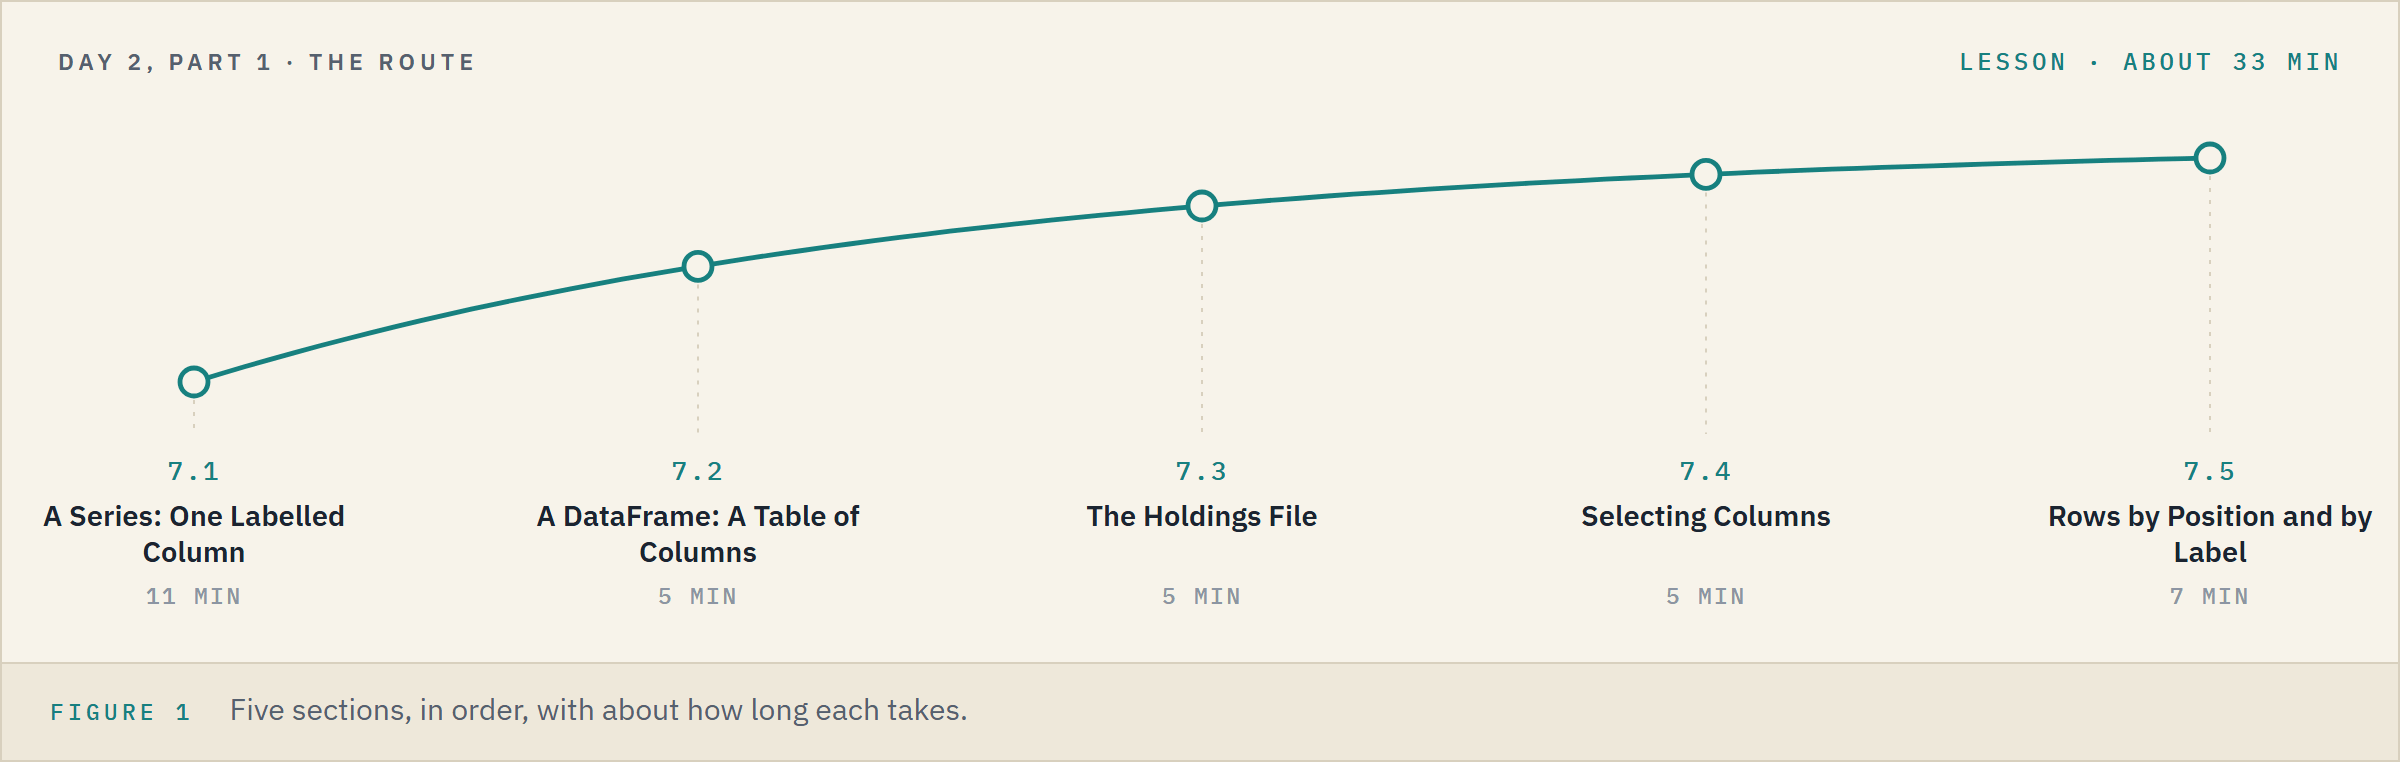

**Time.** About 33 minutes for the lesson, then about 15 for the five exercises.

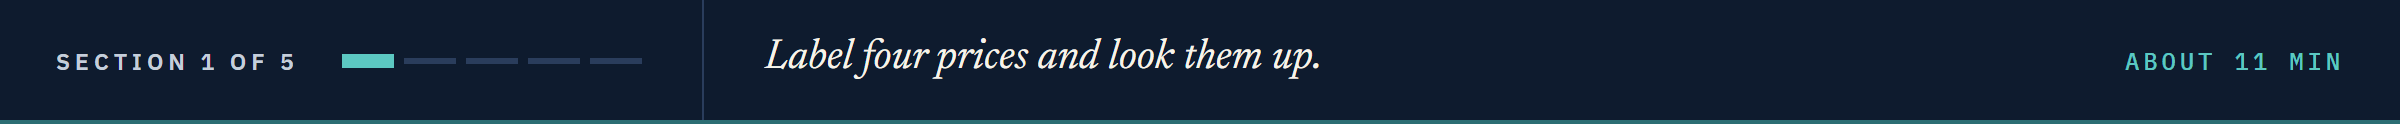

## 7.1 A Series: One Labelled Column

### Four Prices, Then Their Tickers

Q. Put the four prices in a Series, then label each price with its ticker.

In [1]:
# pandas, imported as on Day 0 and Day 5
import pandas as pd
# pd.Series() turns a list into a Series
price_list = [98.5, 103.25, 95.0, 101.0]
print(pd.Series(price_list))
# index= puts a label on each value, in the same order
ticker_list = ['QVNE', 'DNMR', 'PLWK', 'HLVF']
prices = pd.Series(price_list, index=ticker_list)
print(prices)

0     98.50
1    103.25
2     95.00
3    101.00
dtype: float64
QVNE     98.50
DNMR    103.25
PLWK     95.00
HLVF    101.00
dtype: float64


The left column is the **index**: a label on every row; given none, pandas numbers them from 0.

**The label travels with the price.**

### What a Series Holds

Q. What is inside a Series?

In [2]:
# to_numpy() hands back the values as a NumPy array
print(prices.to_numpy())
print(type(prices.to_numpy()))
# .index holds the labels
print(prices.index)

[ 98.5  103.25  95.   101.  ]
<class 'numpy.ndarray'>
Index(['QVNE', 'DNMR', 'PLWK', 'HLVF'], dtype='str')


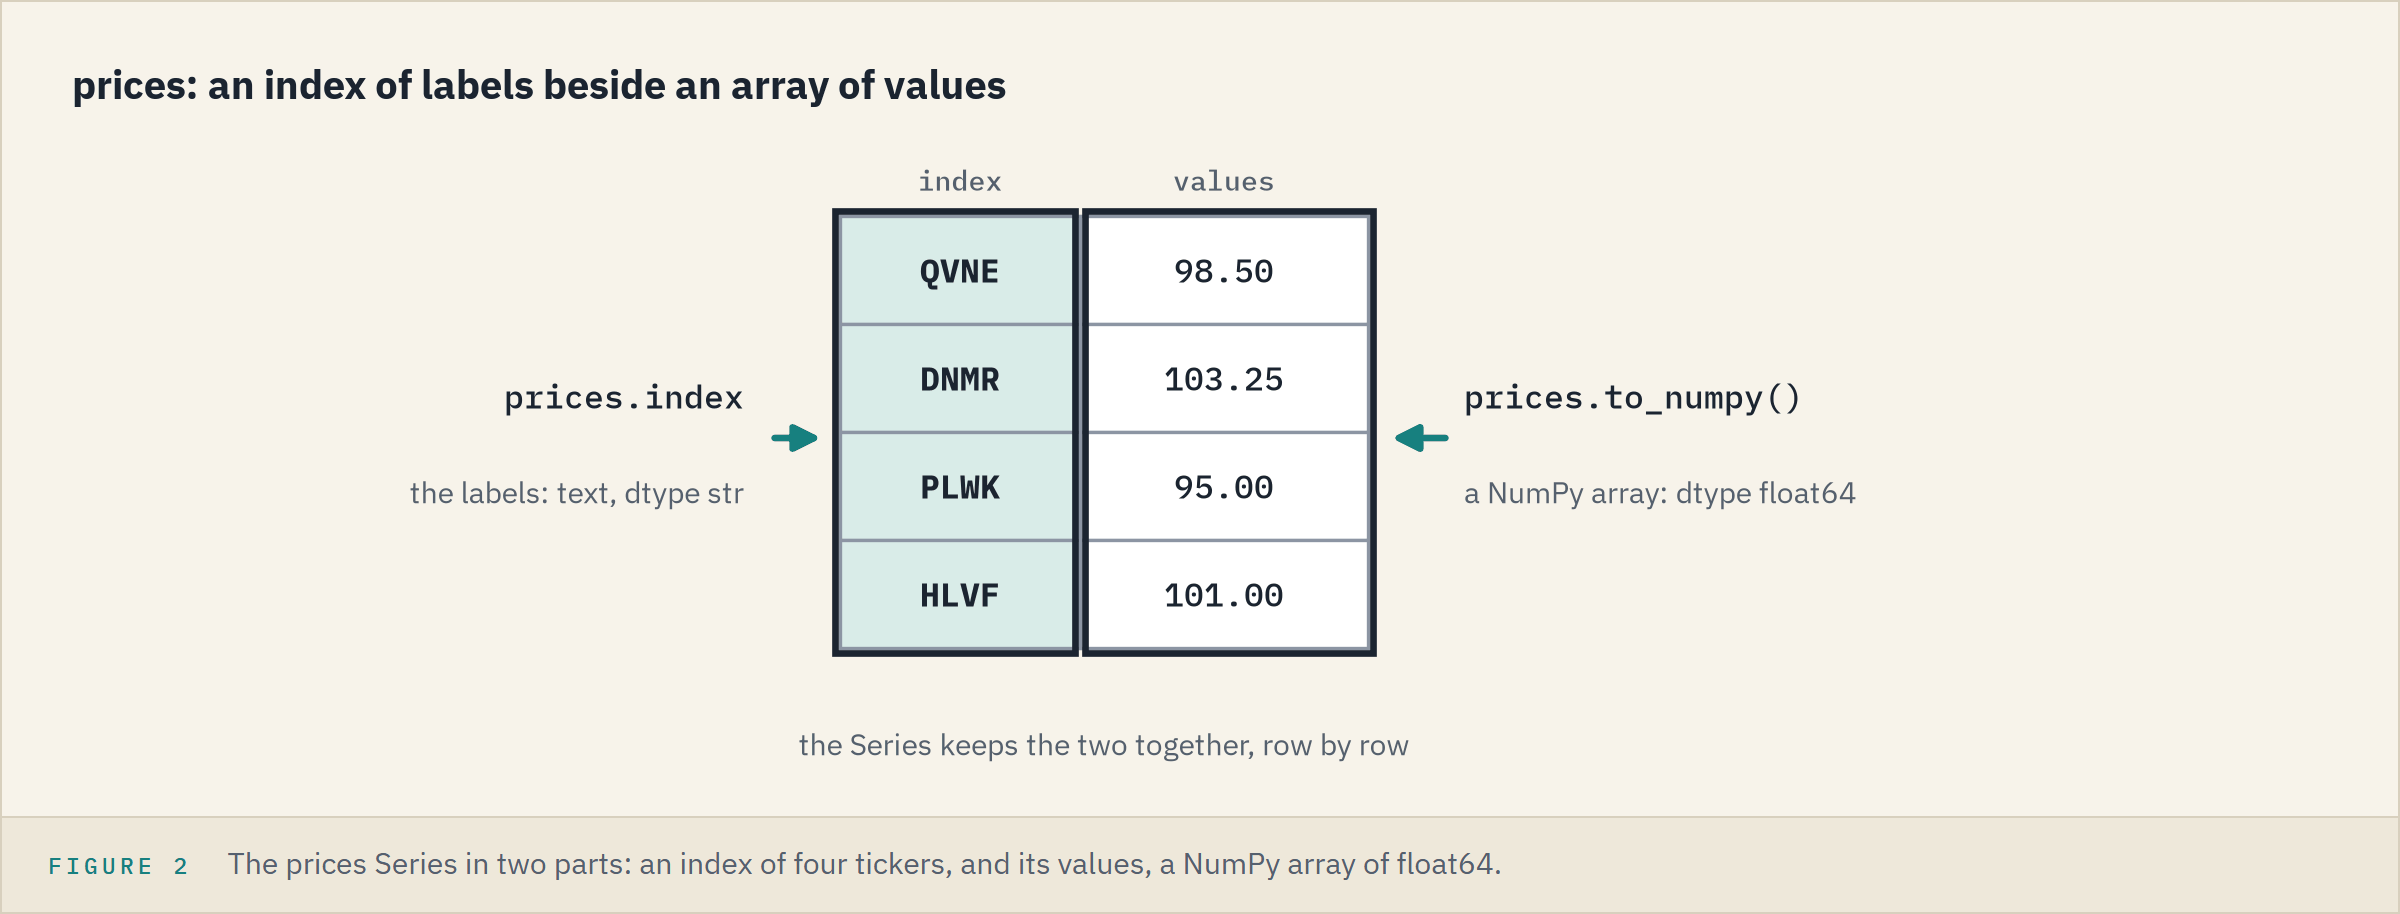

The labels are text, `str` (`object` in older pandas).

**The values are a NumPy array, so NumPy's arithmetic still works.**

### By Label or by Position

Q. What is PLWK's price, and what is the first price?

In [3]:
# a label in square brackets looks up that label's value
print('PLWK:', prices['PLWK'])
# iloc[], integer location, looks up by position, counting from 0
print('First price:', prices.iloc[0])

PLWK: 95.0
First price: 98.5


### A Plain Number in Brackets

**Predict 1**

Q. Many older tutorials look a Series up by a plain number. Here the labels are tickers. What does `prices[0]` give?

A) 98.5, the first price.
B) An error.
C) `QVNE`, the first label.

In [4]:
# a plain number in square brackets, on a Series labelled by tickers
prices[0]

KeyError: 0

B: 0 is not one of the labels.
Older pandas fell back to the position, with a warning; pandas 3 refuses.
Your own run prints pandas' files too; read the last line, as on Day 3.

**Excel side by side.** With the tickers in A2:A5 and the prices in B2:B5:

<table align="left">
<tr><th align="left">Look up</th><th align="left">pandas</th><th align="left">In Python, like</th><th align="left">Excel</th></tr>
<tr><td align="left">by label</td><td align="left"><code>prices['PLWK']</code></td><td align="left">a dictionary key</td><td align="left"><code>=VLOOKUP("PLWK", A2:B5, 2, FALSE)</code></td></tr>
<tr><td align="left">by position</td><td align="left"><code>prices.iloc[0]</code></td><td align="left">a list index, from 0</td><td align="left"><code>=INDEX(B2:B5, 1)</code>, counting from 1</td></tr>
</table>
<br clear="left">

**A label in brackets; a position with `iloc`.**

### Two Labels, Then the Last Two

Q. Show PLWK's and QVNE's prices, in that order, then the last two prices.

In [5]:
# a list of labels: a smaller Series, in the order asked
print(prices[['PLWK', 'QVNE']])
# iloc with a slice: -2: is the last two
print(prices.iloc[-2:])

PLWK    95.0
QVNE    98.5
dtype: float64
PLWK     95.0
HLVF    101.0
dtype: float64


### A Slice by Label

`iloc` has a partner, `loc`, which looks up by label.

**Predict 2**

Q. How many prices does `prices.loc[:'PLWK']` print?

A) Two, QVNE and DNMR: a slice stops before its end.
B) Three: QVNE, DNMR, and PLWK.

In [6]:
# loc with a slice works by label
print(prices.loc[:'PLWK'])

QVNE     98.50
DNMR    103.25
PLWK     95.00
dtype: float64


B: with labels there is no "one past PLWK" to stop before.

**A label slice keeps its end.**

### From a Dictionary or an Array

Q. A colleague sends two prices as a dictionary. Make a Series of it, and one of an array.

In [7]:
# a dictionary: its keys become the index
print(pd.Series({'QVNE': 98.5, 'DNMR': 103.25}))
# an array: numbered from 0
print(pd.Series(prices.to_numpy()))

QVNE     98.50
DNMR    103.25
dtype: float64
0     98.50
1    103.25
2     95.00
3    101.00
dtype: float64


**An array brings no labels; a dictionary brings its keys.**

### The Book's Income, by Ticker

Q. What does each position pay a year? The coupon is in percent of face.

Q. Draw the four incomes.

In [8]:
# two more Series with the same labels
coupons = pd.Series([5.25, 6.125, 4.75, 7.5], index=ticker_list)
faces = pd.Series([1500000, 500000, 750000, 250000], index=ticker_list)
# arithmetic reaches every row, as with arrays
incomes = faces * coupons / 100
print(incomes)
print('Total annual coupon income:', incomes.sum())

QVNE    78750.0
DNMR    30625.0
PLWK    35625.0
HLVF    18750.0
dtype: float64
Total annual coupon income: 163750.0


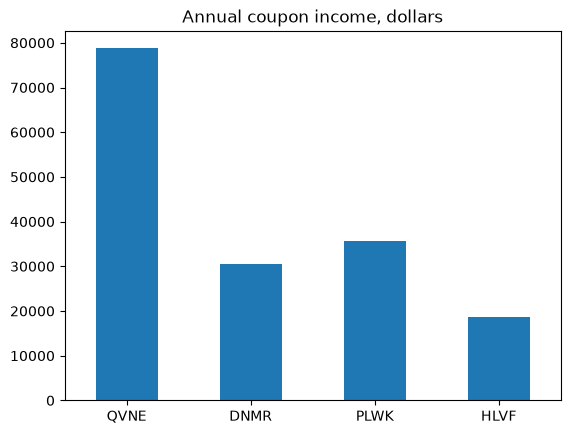

In [9]:
# a Series draws itself, tickers along the bottom; Day 5's table needed x='Ticker'
chart = incomes.plot.bar(rot=0, title='Annual coupon income, dollars')

`mean()`, `min()`, and `max()` work as `sum()` does (Day 5).

**163,750: week 1's number, a ticker on every line.**

### Faces in Another Order

**Predict 3**

Q. The other system sends the faces smallest first: HLVF, DNMR, PLWK, QVNE. `coupons` runs QVNE, DNMR, PLWK, HLVF. What does `faces_by_size * coupons / 100` give?

A) The four right incomes: each face meets its own bond's coupon.
B) Wrong incomes: the first face meets the first coupon, and so on down.
C) An error: the two orders differ.

In [10]:
# the same four faces, smallest position first
faces_by_size = pd.Series([250000, 500000, 750000, 1500000],
                          index=['HLVF', 'DNMR', 'PLWK', 'QVNE'])
print(faces_by_size * coupons / 100)

DNMR    30625.0
HLVF    18750.0
PLWK    35625.0
QVNE    78750.0
dtype: float64


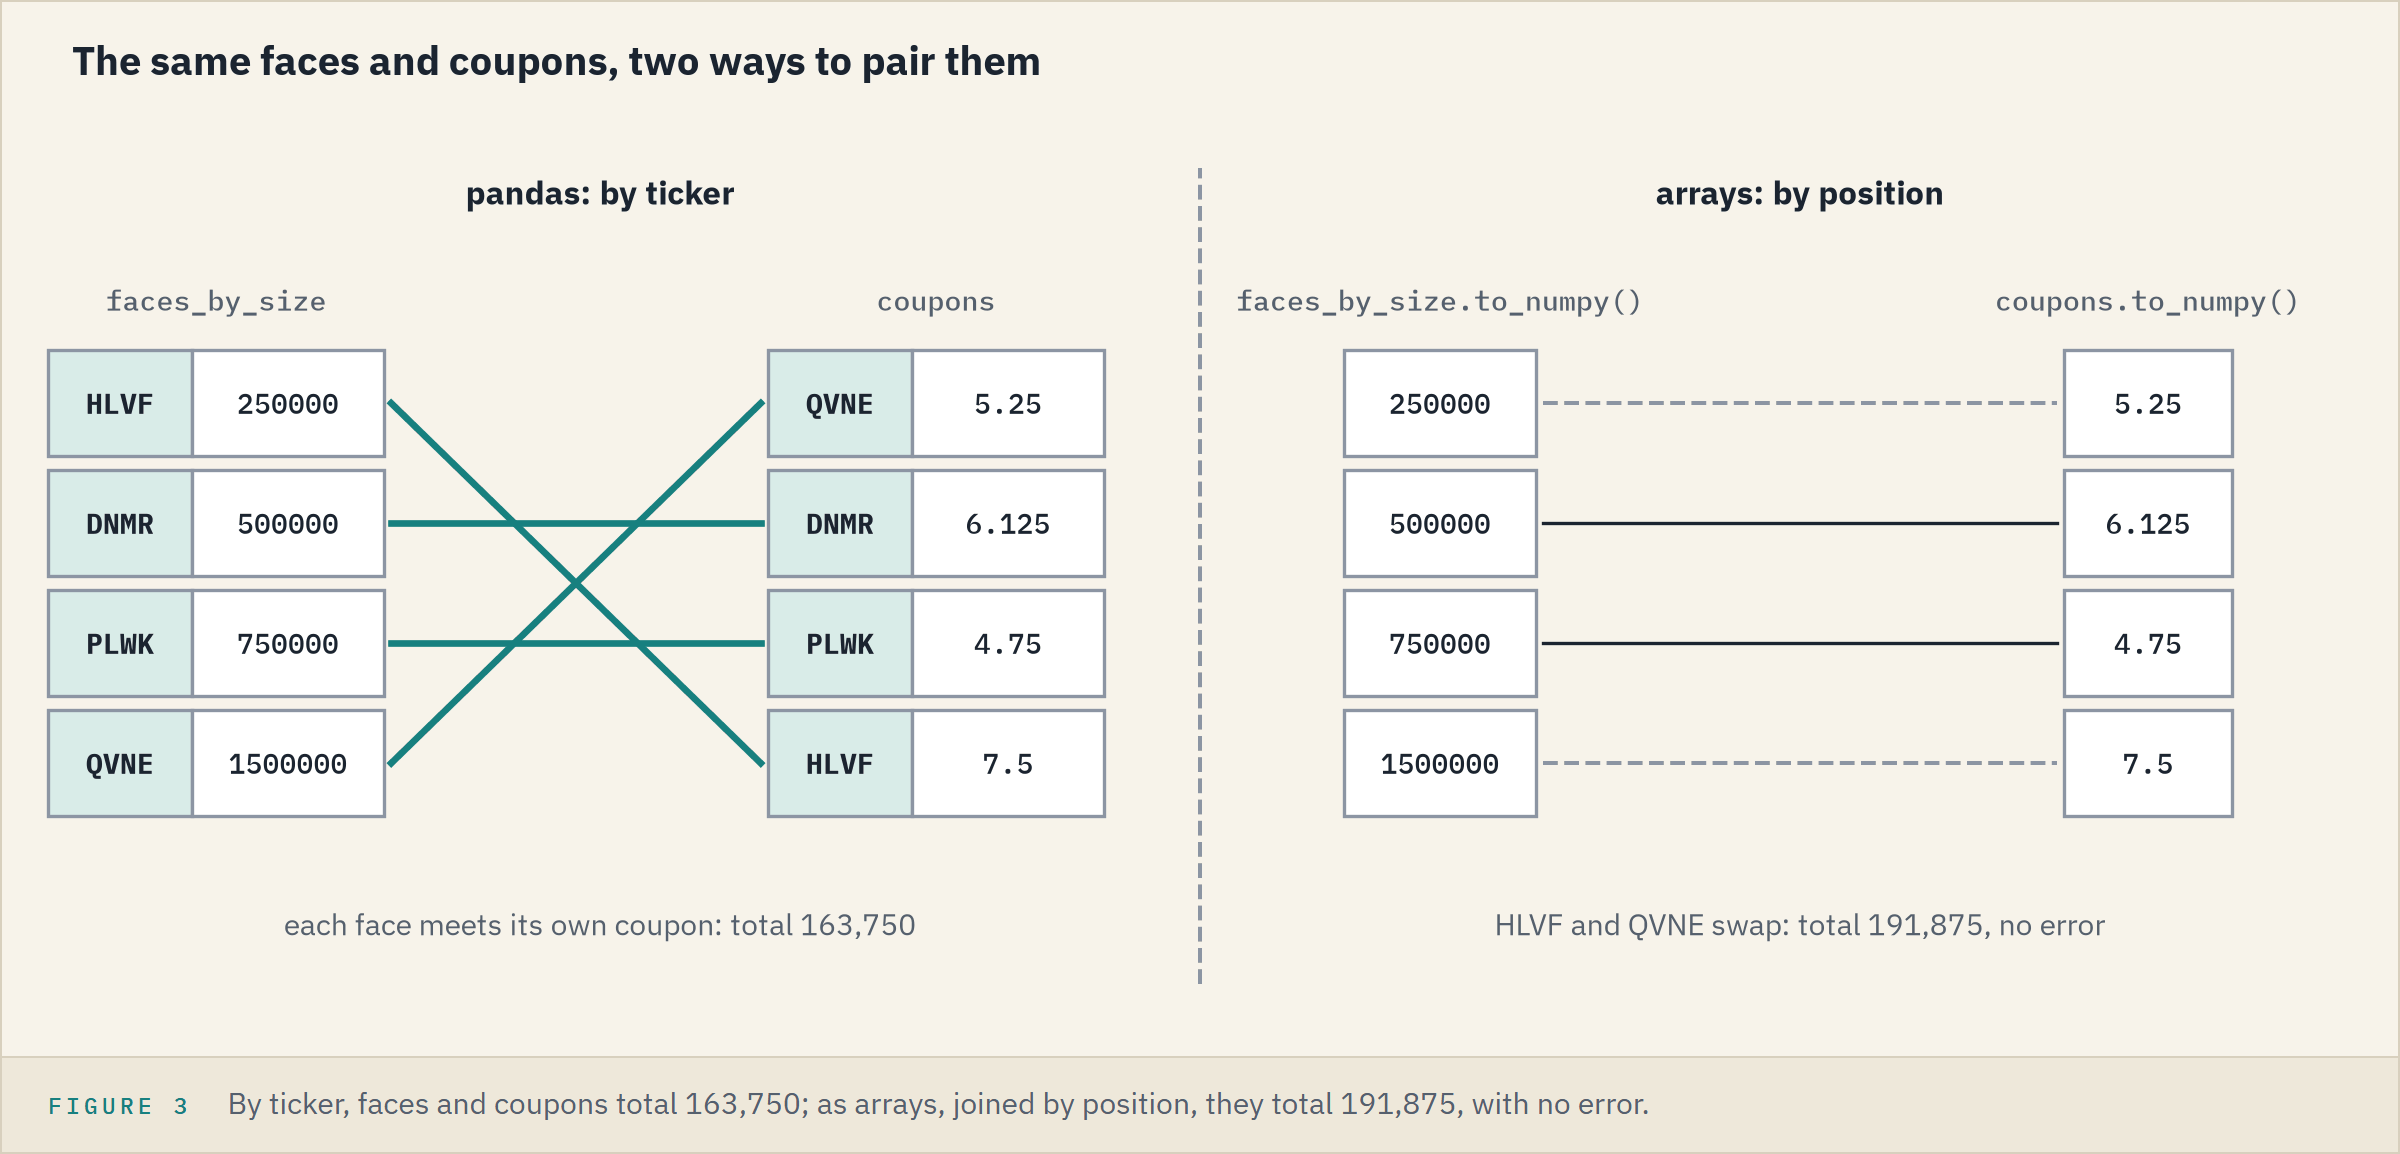

A: pandas matched the two Series by ticker before multiplying.
When the two orders differ, the result prints in sorted label order.

**pandas lines up by label; arrays line up by position, silently.**

### A Bond Left Out

**Predict 4**

Q. Now the other system leaves HLVF out. What do HLVF's income and the total show?

A) An error, as NumPy 6.3 gave for arrays of different sizes.
B) No income for HLVF, and a total of the other three, with no error.
C) The full 163,750.

In [11]:
# drop() returns the Series without that label; faces_by_size is unchanged
faces_missing = faces_by_size.drop('HLVF')
incomes_missing = faces_missing * coupons / 100
print(incomes_missing)
print('Total annual coupon income:', incomes_missing.sum())

DNMR    30625.0
HLVF        NaN
PLWK    35625.0
QVNE    78750.0
dtype: float64
Total annual coupon income: 145000.0


B: HLVF has a coupon and no face, so it comes back `NaN`, "not a number", pandas' mark for a missing value.
`sum()` skips it: 145,000, short HLVF's 18,750, and no error.

**Excel side by side.** With tickers and coupons in A and B, and the other system's in D and E, `=B2*VLOOKUP(A2, D:E, 2, FALSE)/100` filled down does the same matching.
A missing ticker shows `#N/A`, and so does `=SUM()` over the column; pandas shows `NaN` and still totals.

**After arithmetic on two sources, look for `NaN` before trusting a total.**

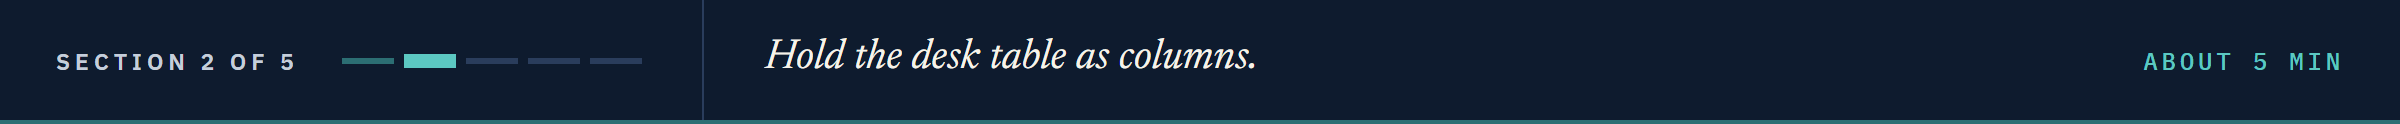

## 7.2 A DataFrame: A Table of Columns

### The Four Bonds as a Table

A DataFrame is Series sharing one index.
Day 5 built one from a dictionary of lists.

Q. Put the four bonds in a DataFrame.

In [12]:
# each key is a column name and each list is a column
desk = pd.DataFrame({
    'Ticker': ['QVNE', 'DNMR', 'PLWK', 'HLVF'],
    'Coupon': [5.25, 6.125, 4.75, 7.5],
    'Maturity': [2033, 2034, 2031, 2032],
    'Price': [98.5, 103.25, 95.0, 101.0],
    'Face': [1500000, 500000, 750000, 250000],
    'Rating': ['BBB', 'BB+', 'A-', 'B+'],
})
desk

,Ticker,Coupon,Maturity,Price,Face,Rating
0,QVNE,5.250,2033,98.50,1500000,BBB
1,DNMR,6.125,2034,103.25,500000,BB+
2,PLWK,4.750,2031,95.00,750000,A-
3,HLVF,7.500,2032,101.00,250000,B+


**Text and numbers side by side: what an array could not hold.**

### Its Names, Types, and Size

Q. What are the table's column names, row labels, column types, and size?

In [13]:
# columns: the names; index: the row labels
print(desk.columns)
print(desk.index)
# dtypes: each column's type; shape: rows, then columns (Day 5)
print(desk.dtypes)
print(desk.shape)

Index(['Ticker', 'Coupon', 'Maturity', 'Price', 'Face', 'Rating'], dtype='str')
RangeIndex(start=0, stop=4, step=1)
Ticker          str
Coupon      float64
Maturity      int64
Price       float64
Face          int64
Rating          str
dtype: object
(4, 6)


`RangeIndex` is the default numbering; like `range()` (week 1's Part 2), it stops before 4.

### A Column Is a Series

Q. Pull the Price column out. What type is it?

In [14]:
# a column name in square brackets selects that column
desk_prices = desk['Price']
print(desk_prices)
print(type(desk_prices))

0     98.50
1    103.25
2     95.00
3    101.00
Name: Price, dtype: float64
<class 'pandas.Series'>


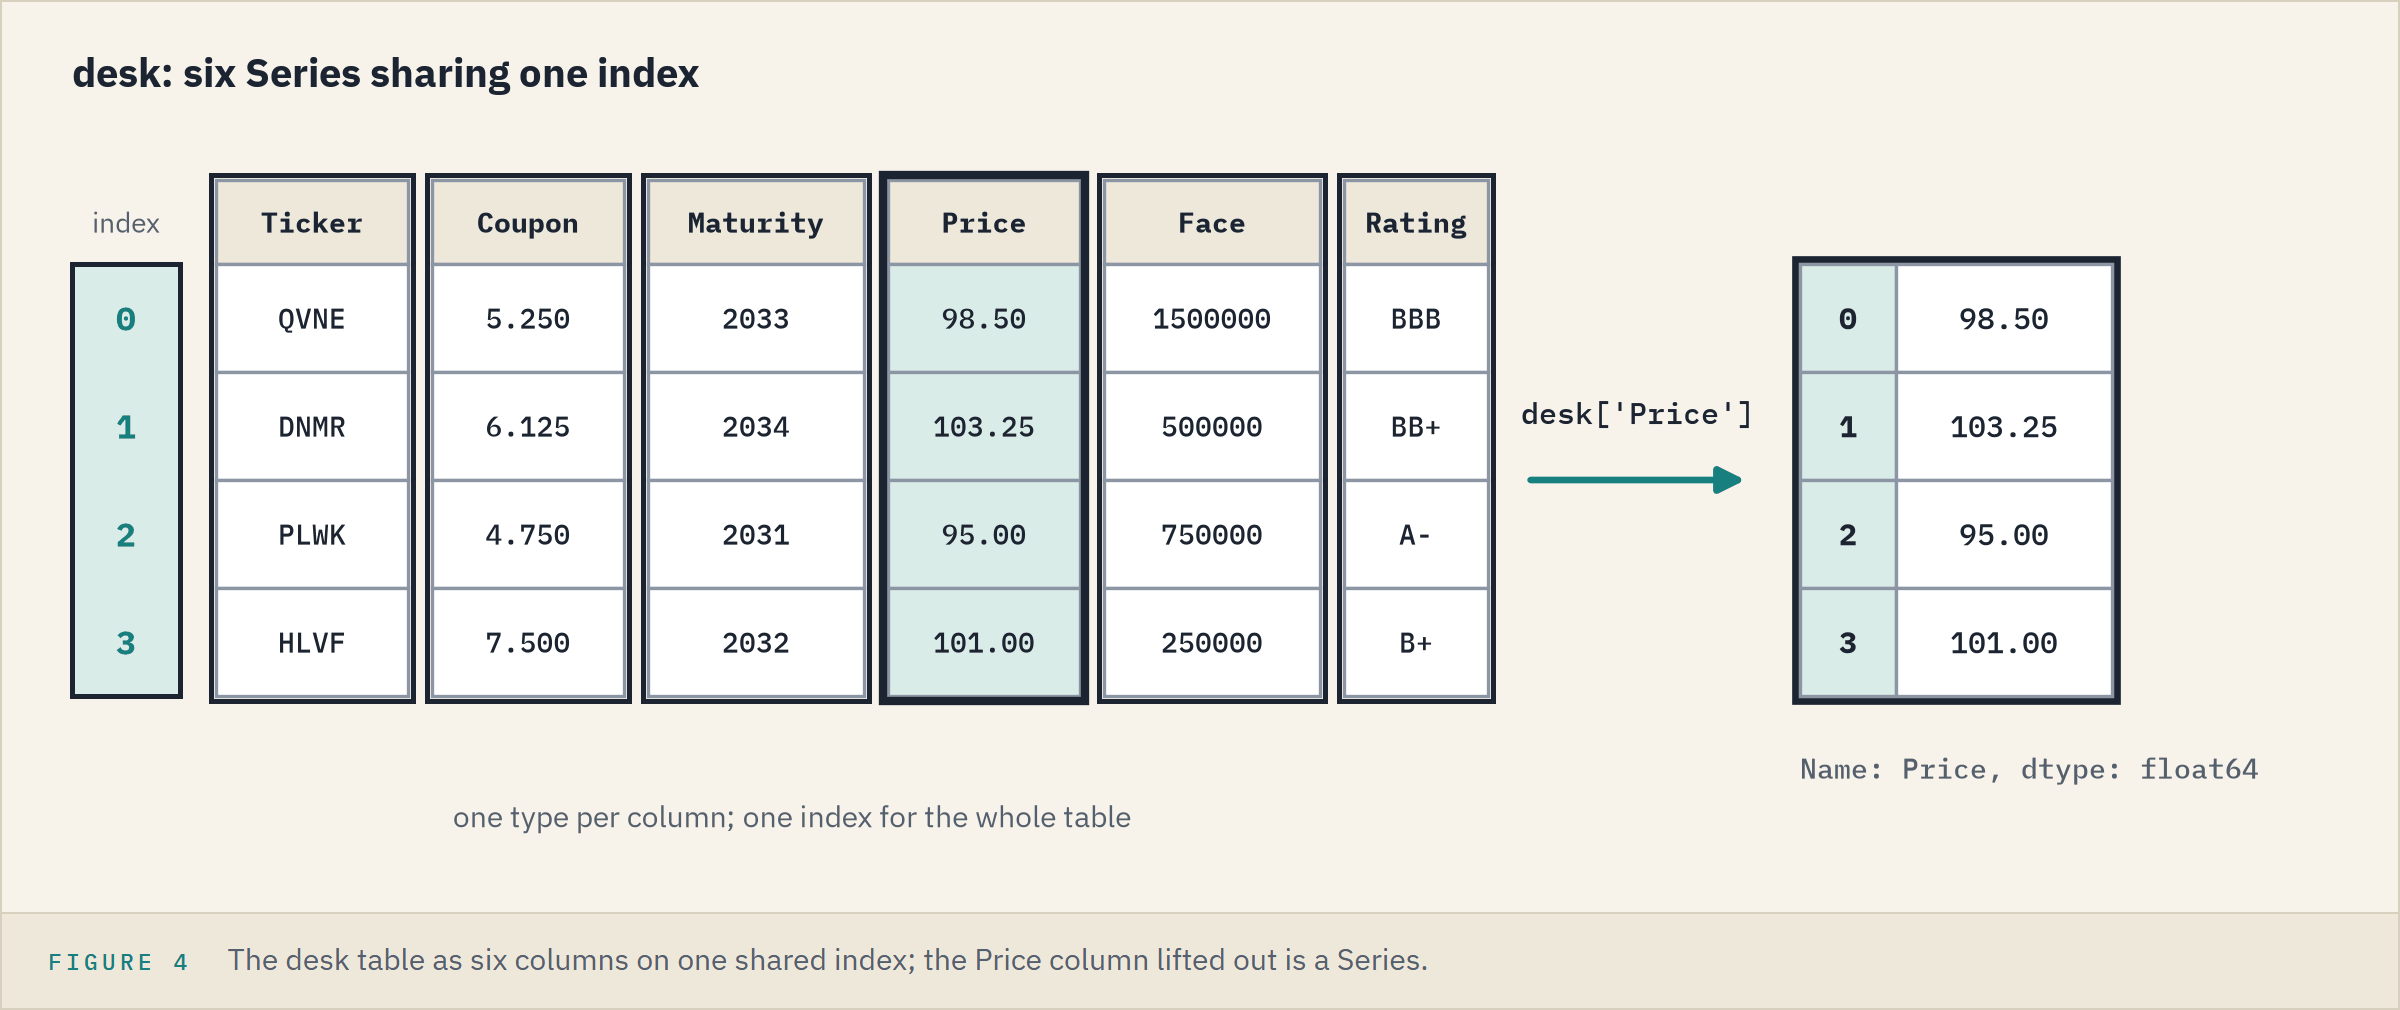

**Everything in 7.1 works on a column.**

### Rows by Slice

Q. Show the first two bonds, every second bond, then all four in reverse.

In [15]:
# a slice in square brackets picks rows, the end left out
print(desk[:2])
# a third number is the step; an empty start or end means the top or the bottom
print(desk[::2])
# a step of -1 walks back from the last row
print(desk[::-1])

  Ticker  Coupon  Maturity   Price     Face Rating
0   QVNE   5.250      2033   98.50  1500000    BBB
1   DNMR   6.125      2034  103.25   500000    BB+
  Ticker  Coupon  Maturity  Price     Face Rating
0   QVNE    5.25      2033   98.5  1500000    BBB
2   PLWK    4.75      2031   95.0   750000     A-
  Ticker  Coupon  Maturity   Price     Face Rating
3   HLVF   7.500      2032  101.00   250000     B+
2   PLWK   4.750      2031   95.00   750000     A-
1   DNMR   6.125      2034  103.25   500000    BB+
0   QVNE   5.250      2033   98.50  1500000    BBB


The row numbers travel with their rows: reversed, QVNE is still 0.

**A name picks columns; a slice picks rows.**

### More Ways to Build a Table

Q. Put 7.1's `coupons` and `faces` side by side in one table.

Q. The risk system sends each bond as a row. Build a table from rows.

In [16]:
# a dictionary of Series: each key a column, the tickers the row labels
book = pd.DataFrame({'Coupon': coupons, 'Face': faces})
print(book)
# a list of rows, each inner list one bond; columns= names the columns
rows = [['QVNE', 5.25, 98.5], ['DNMR', 6.125, 103.25]]
risk = pd.DataFrame(rows, columns=['Ticker', 'Coupon', 'Price'])
print(risk)

      Coupon     Face
QVNE   5.250  1500000
DNMR   6.125   500000
PLWK   4.750   750000
HLVF   7.500   250000
  Ticker  Coupon   Price
0   QVNE   5.250   98.50
1   DNMR   6.125  103.25


<table align="left">
<tr><th align="left">Built from</th><th align="left">Code</th><th align="left">Row labels</th></tr>
<tr><td align="left">a dictionary of lists (Day 5)</td><td align="left"><code>pd.DataFrame({'Price': price_list})</code></td><td align="left">0, 1, 2, ...</td></tr>
<tr><td align="left">a dictionary of Series</td><td align="left"><code>pd.DataFrame({'Coupon': coupons})</code></td><td align="left">the Series' labels, matched as in 7.1</td></tr>
<tr><td align="left">a list of rows</td><td align="left"><code>pd.DataFrame(rows, columns=['Ticker', 'Coupon', 'Price'])</code></td><td align="left">0, 1, 2, ...</td></tr>
<tr><td align="left">a 2-D array (NumPy, Part 2)</td><td align="left"><code>pd.DataFrame(array, columns=[...])</code></td><td align="left">0, 1, 2, ..., or <code>index=</code></td></tr>
</table>
<br clear="left">

**Nobody types two hundred bonds. Load the file.**

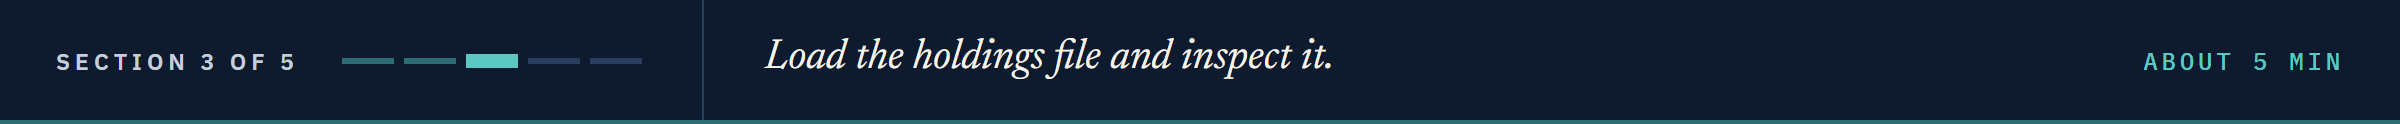

## 7.3 The Holdings File

### Load the File

Q. Load the holdings file into a table.

In [17]:
# '..' is the folder above: three climb from day2 to the repo; in Colab, read from GitHub
import os

if os.path.exists('../../../data/holdings.csv'):
    data_path = '../../../data/holdings.csv'
else:
    data_path = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/holdings.csv'

# read_csv(), as in week 1's Day 2: the first line of the file becomes the column names
holdings = pd.read_csv(data_path)

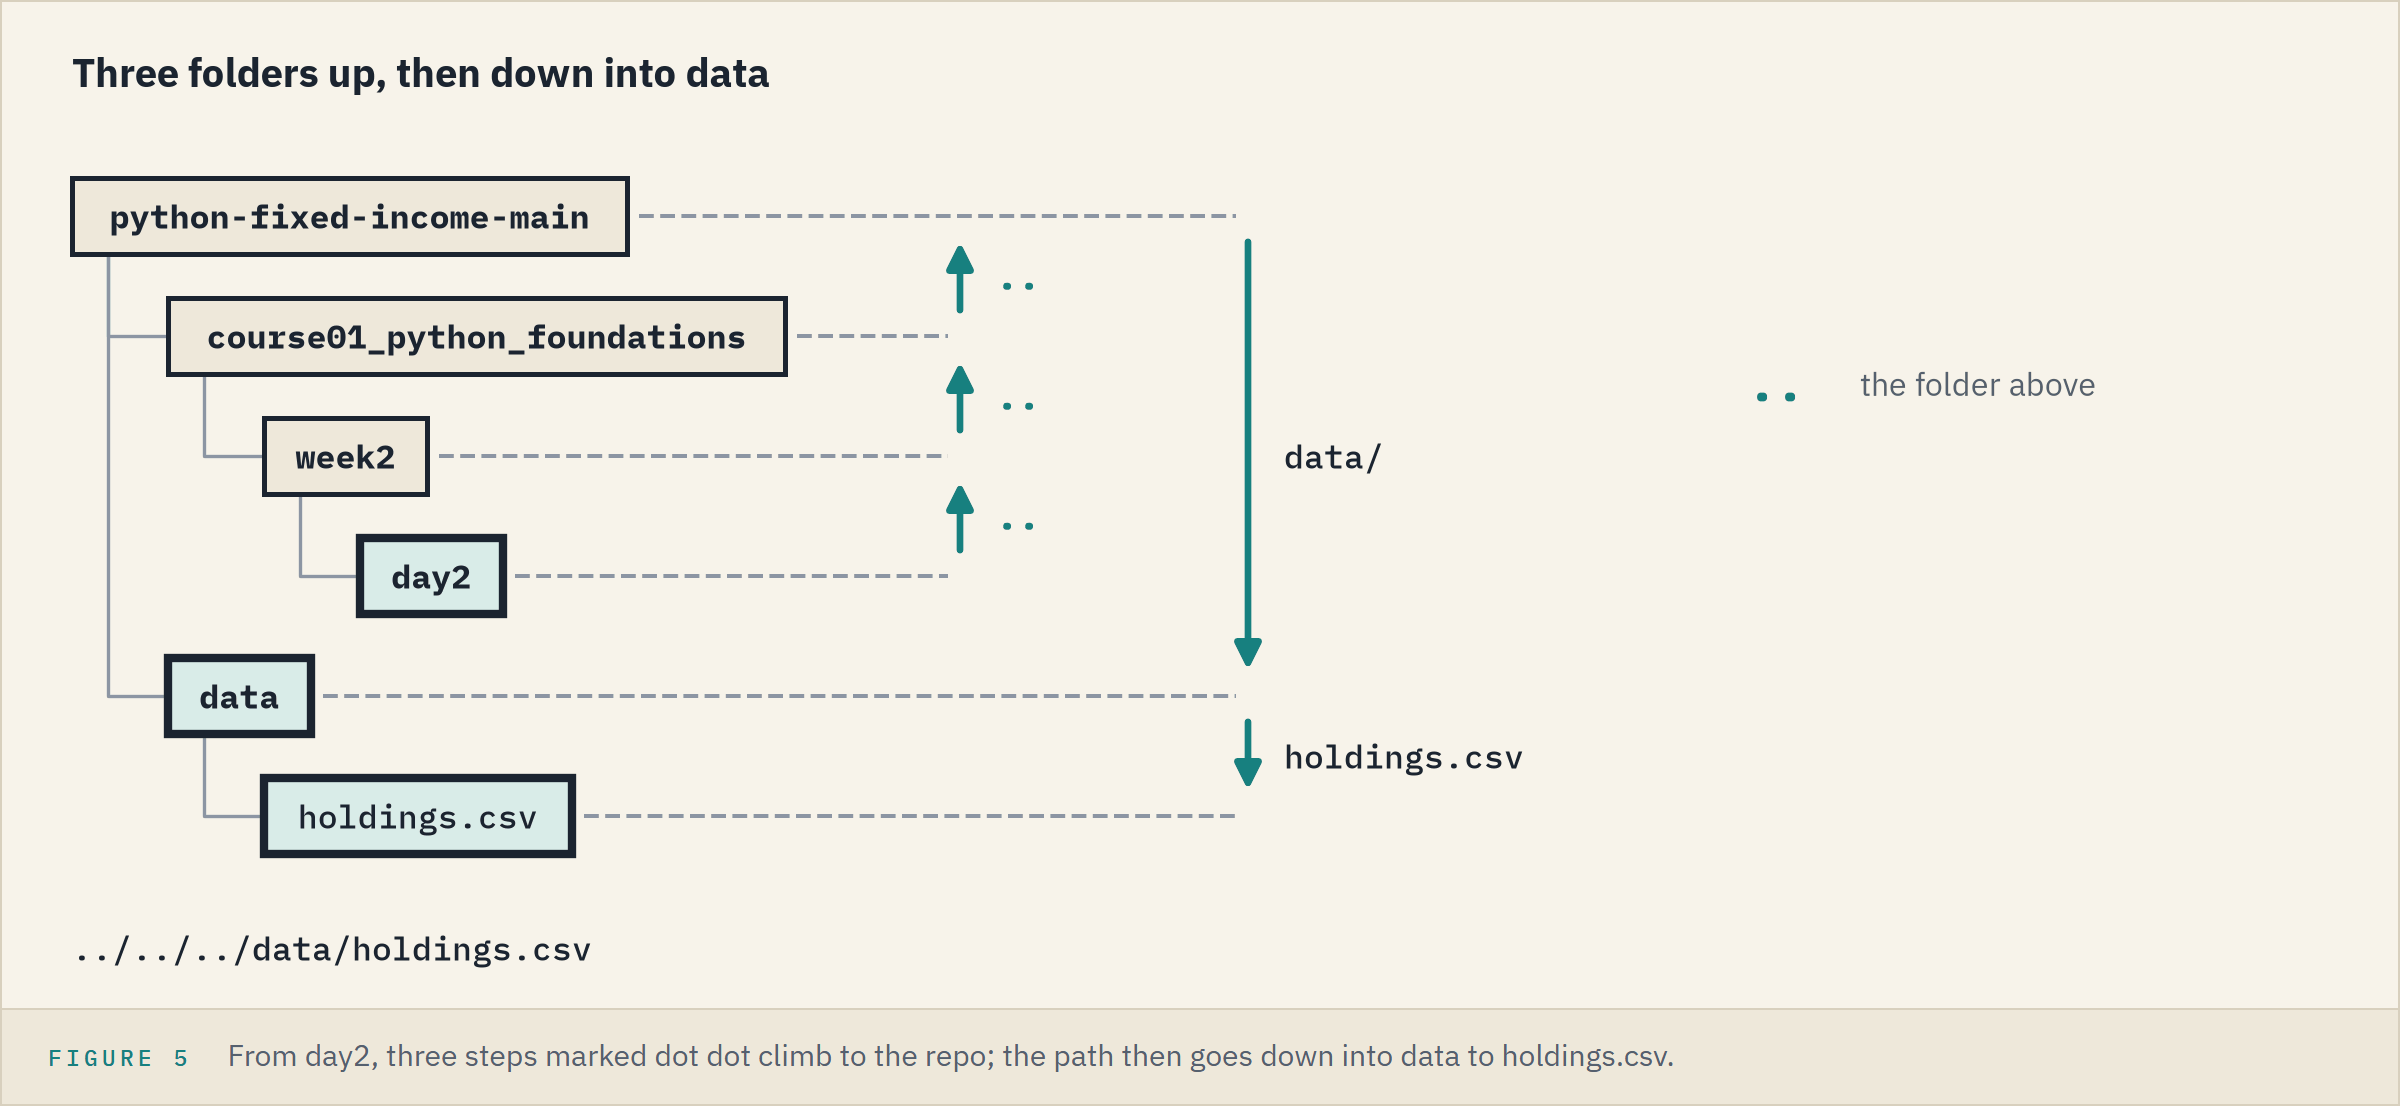

### First and Last Rows

Q. What do the first rows look like, and the last three?

In [18]:
# head(): the first 5 rows; the table is wide, so scroll right
holdings.head()

,as_of_date,cusip,ticker,issuer,sector,rating,coupon,maturity,price,price_date,accrued,yield_pct,oas,duration,spread_duration,dts,amount_outstanding,par_held,market_value
0,2026-09-30,99080CAE8,BEZE,Bezane Finance,Financials,BBB-,7.000,2032-06-18,106.727,2026-09-30,1.983,5.606,147,4.627,4.627,680.2,1650000000,5000000,5435500.0
1,2026-09-30,99049XAE2,BEZH,Bezamyth Machinery,Industrials,B,8.125,2029-04-17,97.556,2026-09-30,3.679,9.220,535,2.165,2.165,1158.3,950000000,250000,253087.5
2,2026-09-30,99039NAC0,BEZL,Bezoquil Freight,Transportation,BB,5.125,2030-06-03,98.730,2026-09-30,1.666,5.509,153,3.250,3.250,497.2,850000000,1500000,1505940.0
3,2026-09-30,99039NAG1,BEZL,Bezoquil Freight,Transportation,BB,6.125,2053-04-09,92.261,2026-09-30,2.909,6.756,218,12.113,12.113,2640.6,2200000000,500000,475850.0
4,2026-09-30,99034IAD4,BEZN,Bezorin Finance,Financials,BBB-,4.625,2036-04-05,92.883,2026-09-30,2.248,5.600,127,7.338,7.338,931.9,1100000000,2500000,2378275.0


In [19]:
# tail(3): the last 3 rows
holdings.tail(3)

,as_of_date,cusip,ticker,issuer,sector,rating,coupon,maturity,price,price_date,accrued,yield_pct,oas,duration,spread_duration,dts,amount_outstanding,par_held,market_value
197,2026-09-30,99062KAA0,ZEPL,Zephizal Medical,Health Care,A-,4.125,2036-11-12,90.863,2026-09-30,1.581,5.303,95,7.919,7.919,752.3,1450000000,1250000,1155550.0
198,2026-09-30,99138IAD9,ZEPN,Zephiskan Resources,Energy,A-,7.250,2031-09-13,110.669,2026-09-30,0.342,4.803,72,4.177,4.177,300.7,2250000000,750000,832582.5
199,2026-09-30,99138IAF4,ZEPN,Zephiskan Resources,Energy,A-,5.000,2036-08-16,93.656,2026-09-30,0.611,5.854,151,7.565,7.565,1142.3,350000000,2500000,2356675.0


Rows 2 and 3 are both BEZL, each bond with its own CUSIP.

**Excel side by side.** Ctrl+End lands on S201: the header in row 1, the bonds in rows 2 to 201, where pandas counts 0 to 199.

**BEZL holds two bonds: a ticker is not a bond.**

### Size, Columns, Types

Q. How big is the table, and what are its columns?

Q. What type is each column, and is anything missing?

In [20]:
# shape: rows, then columns; columns: the names, from the file's first line
print(holdings.shape)
print(holdings.columns)
# info(), Day 5's first look
holdings.info()

(200, 19)
Index(['as_of_date', 'cusip', 'ticker', 'issuer', 'sector', 'rating', 'coupon',
       'maturity', 'price', 'price_date', 'accrued', 'yield_pct', 'oas',
       'duration', 'spread_duration', 'dts', 'amount_outstanding', 'par_held',
       'market_value'],
      dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 19 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   as_of_date          200 non-null    str    
 1   cusip               200 non-null    str    
 2   ticker              200 non-null    str    
 3   issuer              200 non-null    str    
 4   sector              200 non-null    str    
 5   rating              200 non-null    str    
 6   coupon              200 non-null    float64
 7   maturity            200 non-null    str    
 8   price               200 non-null    float64
 9   price_date          200 non-null    str    
 10  accrued             200 non-

All lower case, with underscores for spaces.
A missing value would show as a count under 200.

Every bond is a fixed-rate bullet paying semiannual coupons on a 30/360 day count.

<table align="left">
<tr><th align="left">Column</th><th align="left">Meaning</th><th align="left">Units</th></tr>
<tr><td align="left"><code>as_of_date</code></td><td align="left">Date of the holdings report</td><td align="left">date as text</td></tr>
<tr><td align="left"><code>cusip</code></td><td align="left">Identifier of the bond, invented</td><td align="left">text</td></tr>
<tr><td align="left"><code>ticker</code></td><td align="left">Short code of the issuer</td><td align="left">text</td></tr>
<tr><td align="left"><code>issuer</code></td><td align="left">Name of the issuer, invented</td><td align="left">text</td></tr>
<tr><td align="left"><code>sector</code></td><td align="left">Sector of the issuer</td><td align="left">text</td></tr>
<tr><td align="left"><code>rating</code></td><td align="left">Credit rating of the bond</td><td align="left">text</td></tr>
<tr><td align="left"><code>coupon</code></td><td align="left">Annual coupon</td><td align="left">percent of face</td></tr>
<tr><td align="left"><code>maturity</code></td><td align="left">Maturity date</td><td align="left">date as text</td></tr>
<tr><td align="left"><code>price</code></td><td align="left">Clean price</td><td align="left">per 100 of face</td></tr>
<tr><td align="left"><code>price_date</code></td><td align="left">Date of the price</td><td align="left">date as text</td></tr>
<tr><td align="left"><code>accrued</code></td><td align="left">Accrued interest</td><td align="left">per 100 of face</td></tr>
<tr><td align="left"><code>yield_pct</code></td><td align="left">Yield to maturity</td><td align="left">percent</td></tr>
<tr><td align="left"><code>oas</code></td><td align="left">Option-adjusted spread</td><td align="left">basis points</td></tr>
<tr><td align="left"><code>duration</code></td><td align="left">Modified duration</td><td align="left">years</td></tr>
<tr><td align="left"><code>spread_duration</code></td><td align="left">Spread duration</td><td align="left">years</td></tr>
<tr><td align="left"><code>dts</code></td><td align="left">Duration times spread: <code>spread_duration</code> times <code>oas</code></td><td align="left">years times basis points</td></tr>
<tr><td align="left"><code>amount_outstanding</code></td><td align="left">Size of the whole bond issue</td><td align="left">dollars of face</td></tr>
<tr><td align="left"><code>par_held</code></td><td align="left">Face amount the desk holds</td><td align="left">dollars of face</td></tr>
<tr><td align="left"><code>market_value</code></td><td align="left"><code>par_held</code> times (<code>price</code> plus <code>accrued</code>), divided by 100</td><td align="left">dollars</td></tr>
</table>
<br clear="left">

**Two hundred bonds, 19 columns, nothing missing.**

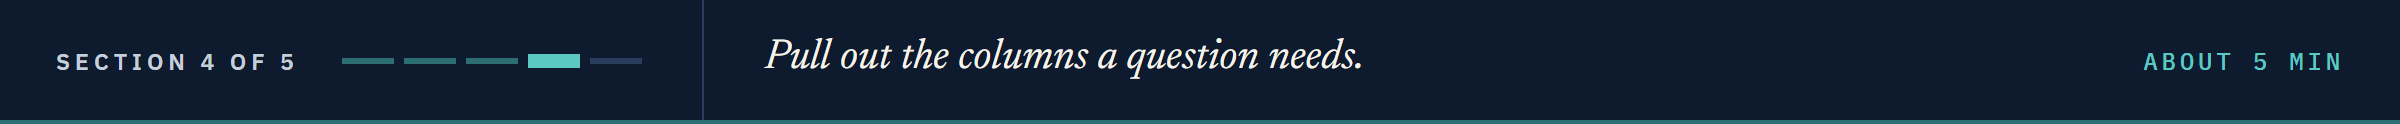

## 7.4 Selecting Columns

### One Column, Then a Name in Capitals

Q. Show the first five bonds' spreads.

On a desk the spread is written OAS.

Q. Then ask for `holdings['OAS']`.

In [21]:
# one name in square brackets: that column, a Series; head() works on a Series too
holdings['oas'].head()

0    147
1    535
2    153
3    218
4    127
Name: oas, dtype: int64

In [22]:
# the column is named oas, in lower case: this cell is meant to fail
holdings['OAS']

KeyError: 'OAS'

Capitals count in a column name, as in a dictionary key (Day 3).

**Spell a column as `holdings.columns` does.**

### A List of Columns

Q. Show the ticker, coupon, maturity, and price of the first five bonds.

In [23]:
# a list of names inside the brackets: a smaller table, in the order asked
holdings[['ticker', 'coupon', 'maturity', 'price']].head()

,ticker,coupon,maturity,price
0,BEZE,7.000,2032-06-18,106.727
1,BEZH,8.125,2029-04-17,97.556
2,BEZL,5.125,2030-06-03,98.730
3,BEZL,6.125,2053-04-09,92.261
4,BEZN,4.625,2036-04-05,92.883


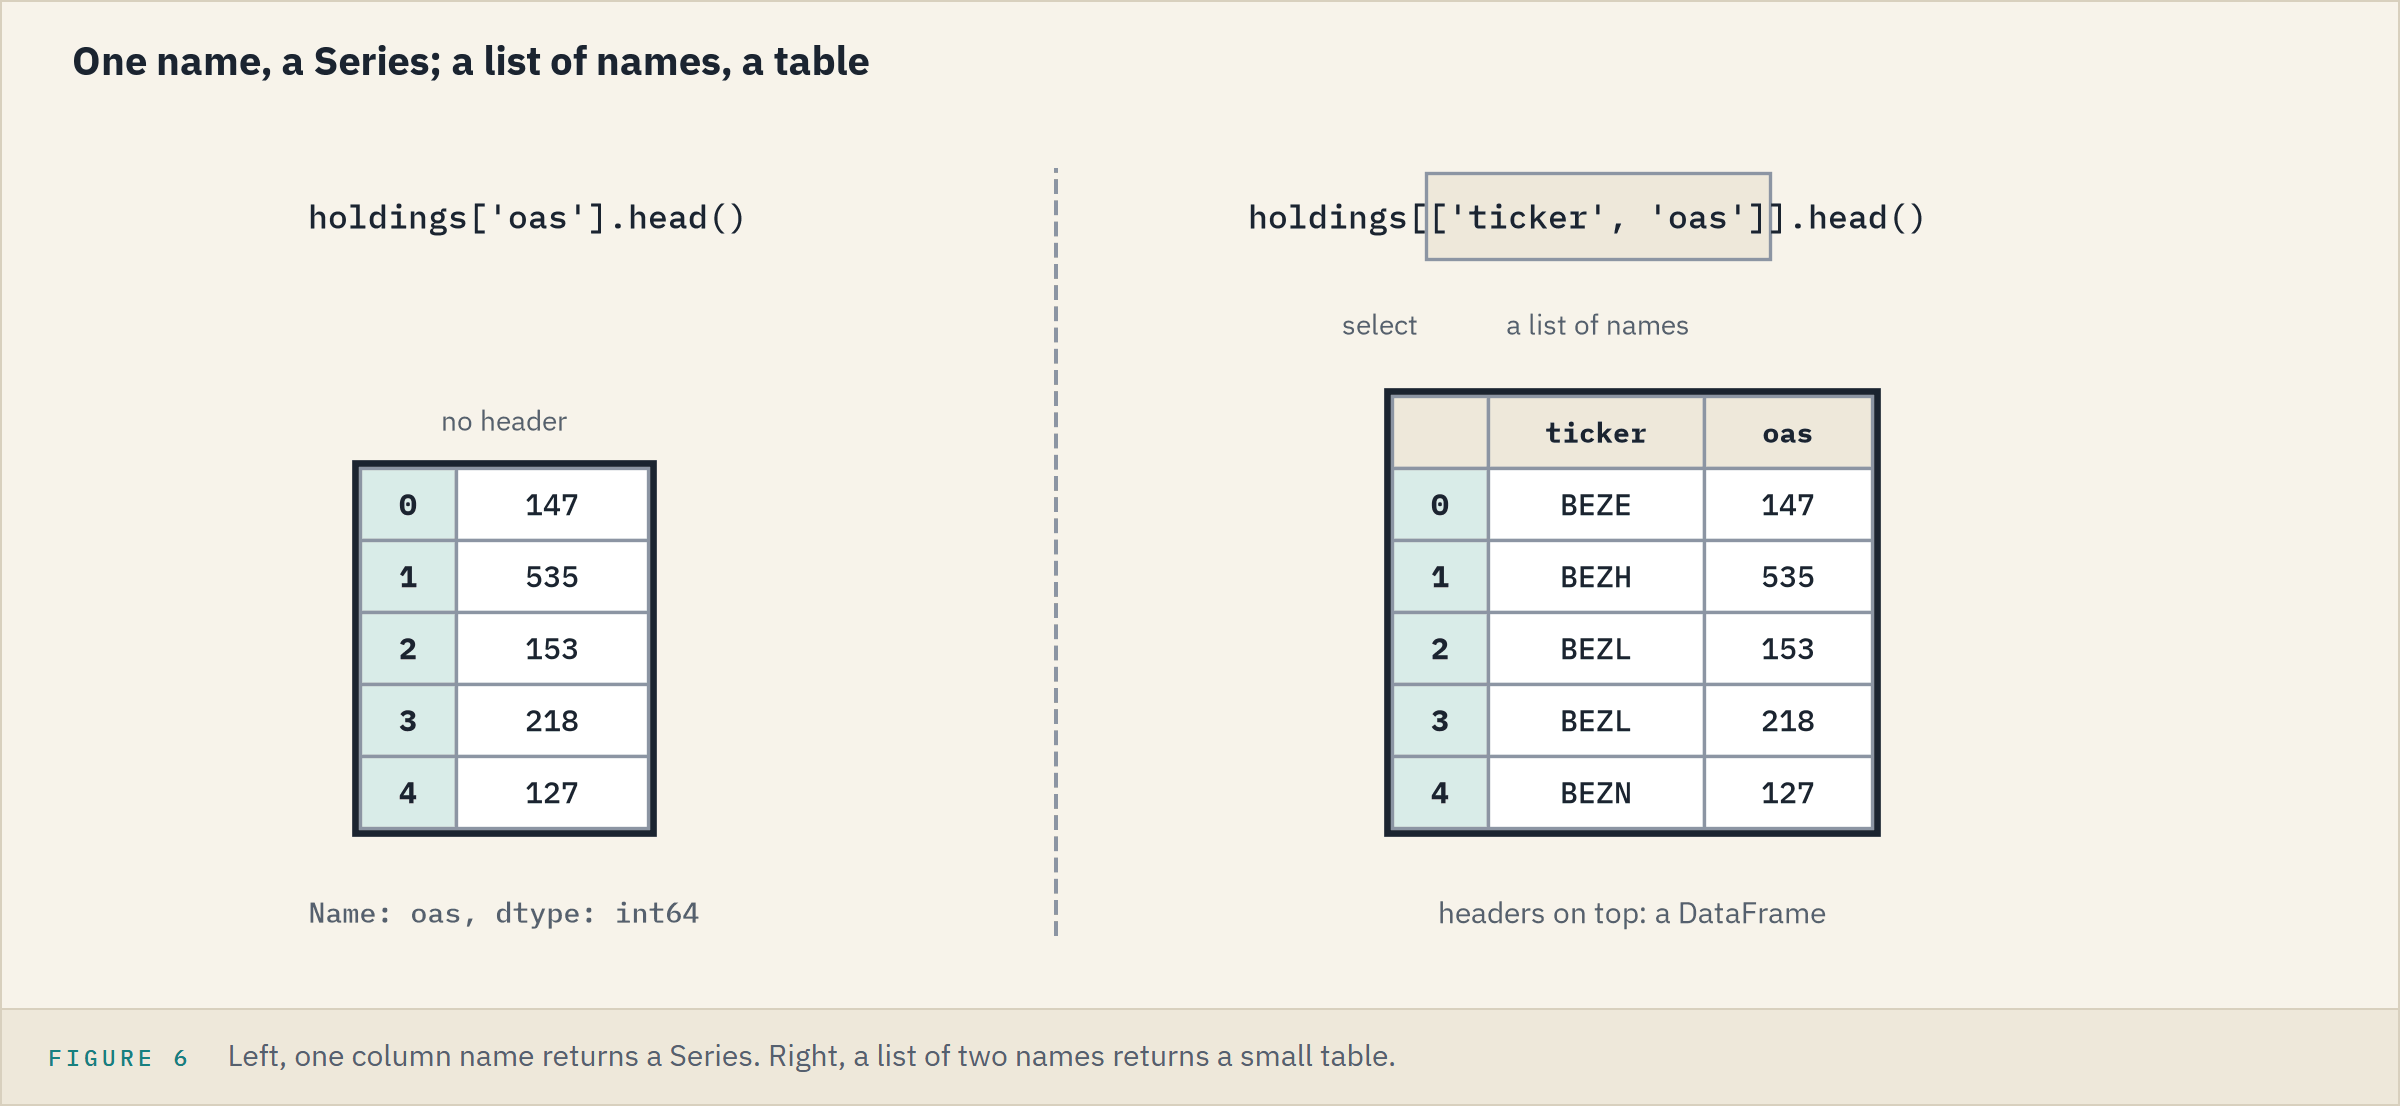

**Excel side by side.** Hiding columns does this on screen; `=CHOOSECOLS(A1:S201, 3, 7, 8, 9)` in Microsoft 365 returns them by number, where pandas goes by name.
A list of one name still gives a table.

**One name, a Series; a list of names, a table.**

### Summarize Five Columns

Q. Summarize the coupon, price, yield, spread, and duration columns.

**Predict 5**

Q. Before it runs: where does the mean spread sit against the median, the middle of the sorted spreads?

A) About the same.
B) Above the median.
C) Below the median.

In [24]:
# describe(), as on Day 5, on five columns
holdings[['coupon', 'price', 'yield_pct', 'oas', 'duration']].describe()

,coupon,price,yield_pct,oas,duration
count,200.000000,200.000000,200.000000,200.000000,200.000000
mean,5.937500,98.828295,6.087815,185.750000,6.470405
std,1.648435,7.404931,1.957543,193.949632,3.350506
min,3.250000,62.045000,4.089000,19.000000,0.927000
25%,4.750000,95.140000,5.058750,81.750000,3.880250
50%,5.687500,99.416000,5.547000,135.500000,6.306500
75%,6.875000,103.004000,6.394500,213.000000,8.139750
max,11.000000,119.131000,19.304000,1551.000000,16.042000


B: the mean, 185.75 bp, sits above the median, the `50%` row, 135.5.
The median price is 99.416: more than half the bonds sit below par.

Q. Draw every bond's spread against its duration.

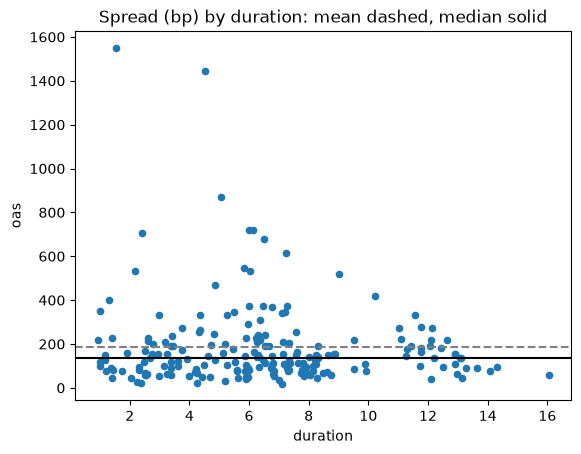

In [25]:
# plot.scatter(): one dot per bond, x= across, y= up
chart = holdings.plot.scatter(x='duration', y='oas',
                              title='Spread (bp) by duration: mean dashed, median solid')
# axhline() as in NumPy 6.4; median(): halfway down the sorted values, describe()'s 50% row
mean_line = chart.axhline(holdings['oas'].mean(), color='grey', linestyle='--')
median_line = chart.axhline(holdings['oas'].median(), color='black')

Most bonds sit under 300 bp; two sit past 1,400.

**A few wide bonds lift the mean above the median. Now the rows.**

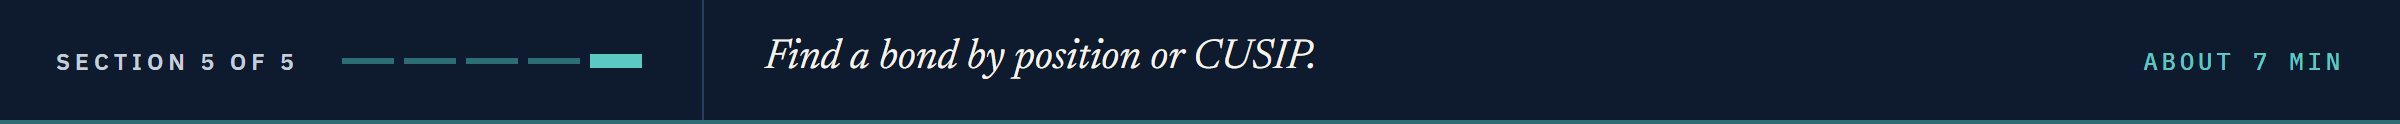

## 7.5 Rows by Position and by Label

### The First Bond, the First Block

A row is picked with 7.1's pair: by position with `iloc`, by label with `loc`.

Q. Show the first bond.

Q. Show the first three bonds, first four columns.

In [26]:
# iloc[0]: the row at position 0
print(holdings.iloc[0])
# iloc[rows, columns], both by position; each slice leaves its end out
holdings.iloc[0:3, 0:4]

as_of_date                2026-09-30
cusip                      99080CAE8
ticker                          BEZE
issuer                Bezane Finance
sector                    Financials
rating                          BBB-
coupon                           7.0
maturity                  2032-06-18
price                        106.727
price_date                2026-09-30
accrued                        1.983
yield_pct                      5.606
oas                              147
duration                       4.627
spread_duration                4.627
dts                            680.2
amount_outstanding        1650000000
par_held                     5000000
market_value               5435500.0
Name: 0, dtype: object


,as_of_date,cusip,ticker,issuer
0,2026-09-30,99080CAE8,BEZE,Bezane Finance
1,2026-09-30,99049XAE2,BEZH,Bezamyth Machinery
2,2026-09-30,99039NAC0,BEZL,Bezoquil Freight


A row comes back as a Series on its side: the column names are its labels.
`dtype: object` is pandas' type for a mix of text and numbers.
`iloc[-1]` is the last row, whatever the table holds.

**Sort the table or drop a bond, and the positions move: a position is not a bond.**

### The CUSIP as Row Label

A label stays with its row, and the CUSIP is the best one: no two bonds share it.

**Predict 6**

Q. After `by_cusip = holdings.set_index('cusip')`, how many columns do `by_cusip` and `holdings` have?

A) 19 and 19: the CUSIP is copied into the index.
B) 18 and 19.
C) 18 and 18.

In [27]:
# set_index('cusip'): use the CUSIP as the row labels
by_cusip = holdings.set_index('cusip')
# shape: rows, then columns, for each table
print(by_cusip.shape, holdings.shape)
by_cusip[['ticker', 'coupon', 'maturity', 'price']].head(3)

(200, 18) (200, 19)


,ticker,coupon,maturity,price
cusip,,,,
99080CAE8,BEZE,7.000,2032-06-18,106.727
99049XAE2,BEZH,8.125,2029-04-17,97.556
99039NAC0,BEZL,5.125,2030-06-03,98.730


B: the CUSIP left the columns to become the row labels; `holdings` is untouched.
Most pandas methods work so: a new table back, the old one left alone.
The ticker would make a poor index: BEZL holds two bonds.

**Any bond is now one CUSIP away.**

### One Bond, Then Its Price

Q. Pull up CUSIP 99039NAC0, then just its price.

In [28]:
# loc[]: a row by its label, wherever it sits
print(by_cusip.loc['99039NAC0'])
# loc[row label, column name]: one value
print(by_cusip.loc['99039NAC0', 'price'])

as_of_date                  2026-09-30
ticker                            BEZL
issuer                Bezoquil Freight
sector                  Transportation
rating                              BB
coupon                           5.125
maturity                    2030-06-03
price                            98.73
price_date                  2026-09-30
accrued                          1.666
yield_pct                        5.509
oas                                153
duration                          3.25
spread_duration                   3.25
dts                              497.2
amount_outstanding           850000000
par_held                       1500000
market_value                 1505940.0
Name: 99039NAC0, dtype: object
98.73


**The note's bond: BEZL 5.125% 2030, rated BB, at 98.73.**

### Two Bonds, Two Ways

Q. Show BEZE's and BEZL's ticker and price, by label, then by position.

Q. Then give `iloc` the column names instead.

In [29]:
# lists of row labels and column names: a smaller table
print(by_cusip.loc[['99080CAE8', '99039NAC0'], ['ticker', 'price']])
# the same by position: rows 0 and 2, columns 2 and 8
print(holdings.iloc[[0, 2], [2, 8]])

          ticker    price
cusip                    
99080CAE8   BEZE  106.727
99039NAC0   BEZL   98.730
  ticker    price
0   BEZE  106.727
2   BEZL   98.730


In [30]:
# column names given to iloc: this cell is meant to fail
holdings.iloc[[0, 2], ['ticker', 'price']]

IndexError: .iloc requires numeric indexers, got ['ticker' 'price']

**`loc` takes labels, `iloc` takes positions.**

### Slices on a Table

Q. Show the first three bonds' tickers twice: by position, then by label from 99080CAE8 to 99039NAC0.

In [31]:
# by position, 0 up to 3
print(by_cusip.iloc[0:3]['ticker'])
# by label, from BEZE's CUSIP to BEZL's
print(by_cusip.loc['99080CAE8':'99039NAC0']['ticker'])

cusip
99080CAE8    BEZE
99049XAE2    BEZH
99039NAC0    BEZL
Name: ticker, dtype: str
cusip
99080CAE8    BEZE
99049XAE2    BEZH
99039NAC0    BEZL
Name: ticker, dtype: str


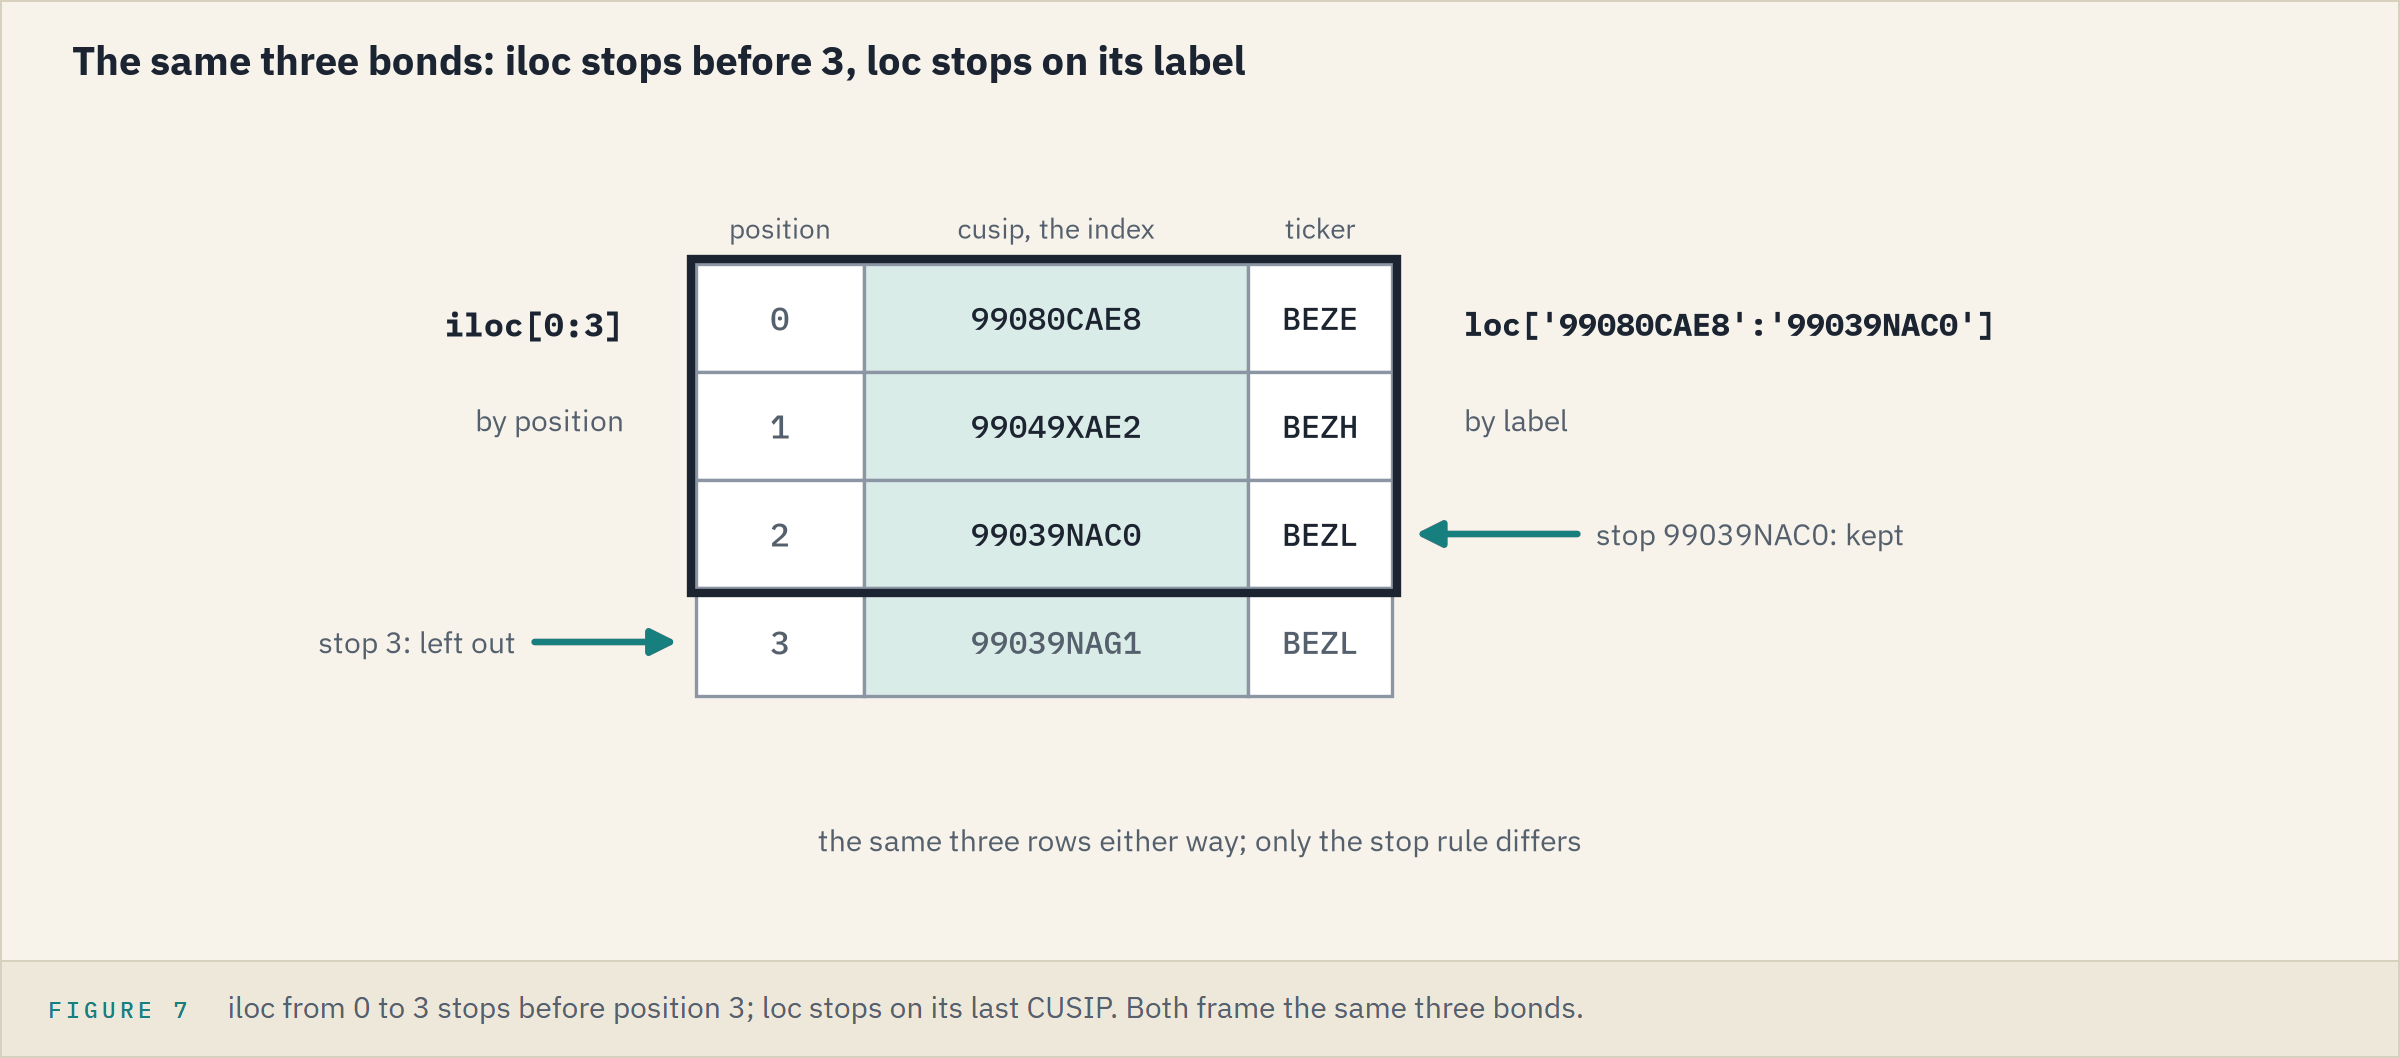

A label slice follows the table's order, not the alphabet's.

**`iloc` stops before its end; `loc` keeps it, as in 7.1.**

### One Wrong Character

Q. Look up BEZE with the last character of its CUSIP mistyped.

In [32]:
# the real CUSIP ends in 8: this cell is meant to fail
by_cusip.loc['99080CAE9']

KeyError: '99080CAE9'

pandas does not guess the nearest match.

**Excel side by side.**

<table align="left">
<tr><th align="left">Question</th><th align="left">pandas</th><th align="left">Excel</th></tr>
<tr><td align="left">The third row</td><td align="left"><code>holdings.iloc[2]</code></td><td align="left">row 4 of the sheet, under the header</td></tr>
<tr><td align="left">The first three bonds, first four columns</td><td align="left"><code>holdings.iloc[0:3, 0:4]</code></td><td align="left"><code>=TAKE(A2:S201, 3, 4)</code>, Microsoft 365</td></tr>
<tr><td align="left">Price of a CUSIP</td><td align="left"><code>by_cusip.loc['99039NAC0', 'price']</code></td><td align="left"><code>=VLOOKUP("99039NAC0", B:I, 8, FALSE)</code></td></tr>
<tr><td align="left">The same, without counting columns</td><td align="left"><code>by_cusip.loc['99039NAC0', 'price']</code></td><td align="left"><code>=INDEX(I:I, MATCH("99039NAC0", B:B, 0))</code></td></tr>
<tr><td align="left">A CUSIP that is not there</td><td align="left"><code>KeyError</code></td><td align="left"><code>#N/A</code></td></tr>
</table>
<br clear="left">

The CUSIP sits in column B and the price in column I, as in `holdings.csv`.
`loc` is `INDEX` and `MATCH` in one step, by the column's name.

**A lookup that fails loudly is the one a desk wants.**

## You Can Now

By the end of this notebook, you can:

* Build a Series and a DataFrame from lists, a dictionary, Series, or rows.
* Say what an index is, and why pandas lines two Series up by label.
* Look for `NaN` after arithmetic on two sources, before trusting a total.
* Load a holdings file and take a first look: its size, columns, types, and anything missing.
* Pull out the columns a question needs: one name for a Series, a list for a table.
* Look a bond up by its CUSIP with `loc`, and pick rows and columns by position with `iloc`.

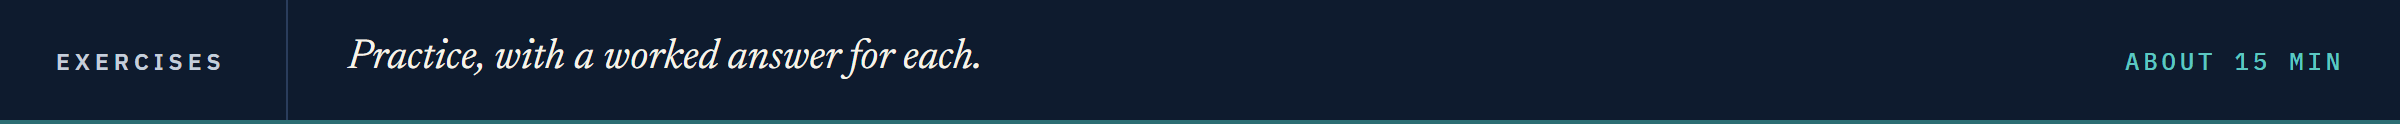

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

The exercises use the second desk's three bonds, below, and the holdings file; the issuers are invented.

<table align="left">
<tr><th align="left">Ticker</th><th align="left">Coupon (%)</th><th align="left">Price</th><th align="left">Face held</th></tr>
<tr><td align="left">TRNW</td><td align="left">4.375</td><td align="left">96.25</td><td align="left">2,000,000</td></tr>
<tr><td align="left">OSMC</td><td align="left">5.00</td><td align="left">100.00</td><td align="left">1,250,000</td></tr>
<tr><td align="left">CLDB</td><td align="left">8.25</td><td align="left">104.50</td><td align="left">500,000</td></tr>
</table>
<br clear="left">

Replace each `...` with your own code, then run the check cell under it.
Run the next cell first: it loads a fresh copy of the holdings and defines `check`, which marks your answers.

In [33]:
import os

import pandas as pd


def check(label, answer, expected):
    """Compare an exercise answer to the expected value and print the result."""
    if answer is ... or answer is None:
        print(label + ': not attempted yet')
        return
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text;
    # isinstance(expected, list) is True when expected is a list
    if getattr(answer, 'ndim', 0) > 0 and not isinstance(expected, list):
        # a whole column or table was stored where a single value is expected
        print(label + ': not yet. A single value is expected, and you have a column or a table.')
        return
    if isinstance(expected, list):
        # a list of values: the same values in the same order
        correct = list(answer) == expected
    elif isinstance(expected, float):
        # single numbers with a decimal point: within a small tolerance;
        # abs() drops the sign, so this is the size of the gap between the two
        correct = abs(answer - expected) < 0.000001
    else:
        correct = answer == expected
    if correct:
        print(label + ': correct')
    else:
        print(label + ': not yet. You have', answer)


# a fresh copy of the holdings. In Colab it is read from GitHub.
if os.path.exists('../../../data/holdings.csv'):
    data_path = '../../../data/holdings.csv'
else:
    data_path = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/holdings.csv'

holdings = pd.read_csv(data_path)
print(holdings.shape)

(200, 19)


### Exercise 1

Q. Put the prices, the coupons, and the face amounts of the second desk in three Series, each labelled with the tickers. Look up the price of OSMC by its label and store it in **ex1_osmc_price**. Look up the last price by its position and store it in **ex1_last_price**. Then find the total annual coupon income and store it in **ex1_income**.

In [34]:
ex1_osmc_price = ...
ex1_last_price = ...
ex1_income = ...

In [35]:
check('Exercise 1 OSMC price', ex1_osmc_price, 100.0)
check('Exercise 1 last price', ex1_last_price, 104.5)
check('Exercise 1 income', ex1_income, 191250.0)

Exercise 1 OSMC price: not attempted yet
Exercise 1 last price: not attempted yet
Exercise 1 income: not attempted yet


### Exercise 2

Q. Put the second desk in a DataFrame named **ex2_desk**, with the columns `Ticker`, `Coupon`, `Price`, and `Face`. Store its number of rows in **ex2_rows** and its number of columns in **ex2_columns**. Then pull out the `Price` column and store its average in **ex2_avg_price**.

In [36]:
ex2_desk = ...
ex2_rows = ...
ex2_columns = ...
ex2_avg_price = ...

In [37]:
check('Exercise 2 rows', ex2_rows, 3)
check('Exercise 2 columns', ex2_columns, 4)
check('Exercise 2 average price', ex2_avg_price, 100.25)

Exercise 2 rows: not attempted yet
Exercise 2 columns: not attempted yet
Exercise 2 average price: not attempted yet


### Exercise 3

Q. From the holdings, keep only the `ticker`, `sector`, `rating`, and `oas` columns, in a table named **ex3_table**. Store its number of columns in **ex3_columns**. Then find the highest yield in the file and the lowest coupon, and store them in **ex3_max_yield** and **ex3_min_coupon**.

In [38]:
ex3_table = ...
ex3_columns = ...
ex3_max_yield = ...
ex3_min_coupon = ...

In [39]:
check('Exercise 3 columns', ex3_columns, 4)
check('Exercise 3 highest yield', ex3_max_yield, 19.304)
check('Exercise 3 lowest coupon', ex3_min_coupon, 3.25)

Exercise 3 columns: not attempted yet
Exercise 3 highest yield: not attempted yet
Exercise 3 lowest coupon: not attempted yet


### Exercise 4

Q. Make a table indexed by CUSIP and use `loc` to look up the price and the rating of the bond with CUSIP 99071TAG7. Store them in **ex4_price** and **ex4_rating**. Then use `iloc` on the holdings to find the ticker of the last bond in the file, and store it in **ex4_last_ticker**.

In [40]:
ex4_price = ...
ex4_rating = ...
ex4_last_ticker = ...

In [41]:
check('Exercise 4 price', ex4_price, 97.612)
check('Exercise 4 rating', ex4_rating, 'A-')
check('Exercise 4 last ticker', ex4_last_ticker, 'ZEPN')

Exercise 4 price: not attempted yet
Exercise 4 rating: not attempted yet
Exercise 4 last ticker: not attempted yet


### Exercise 5: AI check

The second desk's face amounts arrive from another system, listed from the smallest position to the largest.

You ask an AI assistant for the total annual coupon income; it has one bug.

Q. Read the code before you run it. What number do you expect? You worked out the income yourself in Exercise 1. Then run the code. Does it agree with you?

Q. Find the bug and fix the code in the cell below, so that **ex5_income** holds the right answer.

In [42]:
# written for this course in the style of an AI assistant's answer. It contains one bug.
ai_coupons = pd.Series([4.375, 5.0, 8.25], index=['TRNW', 'OSMC', 'CLDB'])
ai_faces = pd.Series([500000, 1250000, 2000000], index=['CLDB', 'OSMC', 'TRNW'])

# the income of each position, then the total
ex5_income = (ai_faces.to_numpy() * ai_coupons / 100).sum()
print(f'Total annual coupon income: {ex5_income:,.0f}')

Total annual coupon income: 249,375


In [43]:
check('Exercise 5 income', ex5_income, 191250.0)

Exercise 5 income: not yet. You have 249375.0


## Congratulations!

<table align="left">
<tr><th align="left">The note asked</th><th align="left">Answer</th></tr>
<tr><td align="left">Names on our four bonds</td><td align="left">a Series and a table, a ticker on every row</td></tr>
<tr><td align="left">Faces in the other system's order</td><td align="left">163,750 again: pandas lined them up by ticker</td></tr>
<tr><td align="left">One bond left out</td><td align="left"><code>NaN</code> for HLVF, and a total short by its 18,750</td></tr>
<tr><td align="left">How big, which columns, anything missing</td><td align="left">200 bonds, 19 columns, nothing missing</td></tr>
<tr><td align="left">The spreads</td><td align="left">median 135.5 bp, mean 185.75, a few wide bonds out to 1,551</td></tr>
<tr><td align="left">CUSIP 99039NAC0 and its price</td><td align="left">BEZL 5.125% 2030, at 98.73</td></tr>
</table>
<br clear="left">

Be proud: this morning you had four bonds typed by hand; now you load two hundred and find any one by its CUSIP.

In Part 2 the table starts answering questions: totals and counts, the bonds that pass a test, the book in order, a what-if on a copy, and a table shown well.

[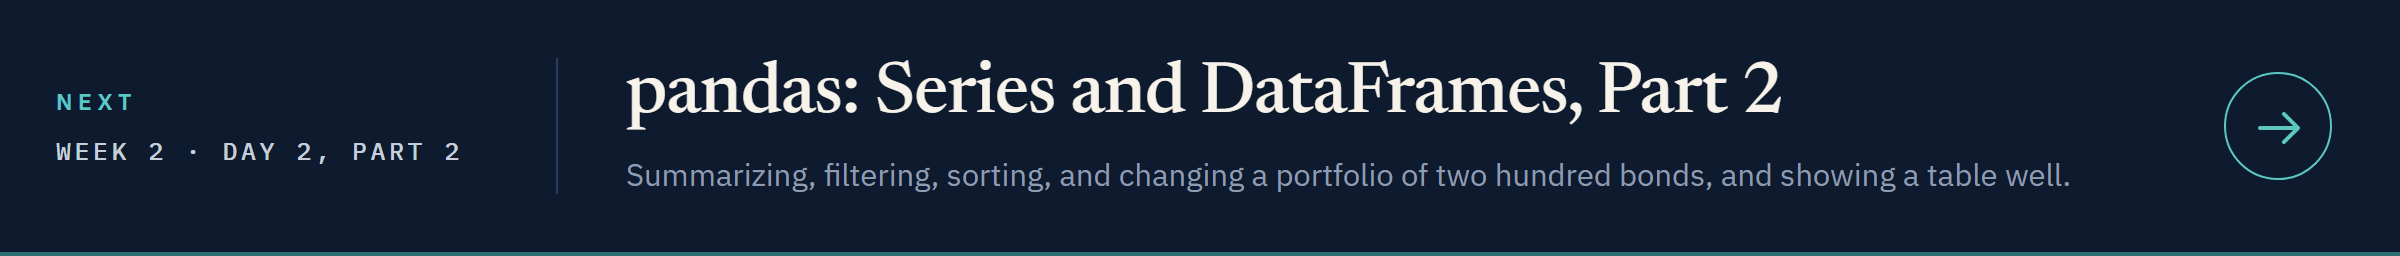](../day2_part2/07_part2_pandas_series_and_dataframes.ipynb)

[Open Day 2, Part 2 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week2/day2_part2/07_part2_pandas_series_and_dataframes.ipynb)